# The Fifth Model
the data here is indoor and planetary

### Installing dependencies

In [ ]:
!nvidia-smi

Mon Jul  6 06:03:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.4.89 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 52.1/118.9 GB disk)


### Download dataset

In [ ]:
from roboflow import Roboflow
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path

SOURCE_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_model"

ROBOFLOW_API_KEY = "CRCuv0GDaHnAbuNRrtlu"
# WORKSPACE = "Harshitas Workspace"
WORKSPACE = "harshitas-workspace-kk712"
PROJECT = "indoor_obstacle_model"
VERSION = 2

rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE).project(PROJECT)
dataset = project.version(VERSION).download("coco-segmentation", location=SOURCE_DIR)

print("Downloaded to:", SOURCE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/drive/MyDrive/ISRO/Model_4_3/Instance_model in coco-segmentation:: 100%|██████████| 1094/1094 [00:09<00:00, 112.11it/s]

Downloaded to: /content/drive/MyDrive/ISRO/Model_4_3/Instance_model


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

SOURCE_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_model"
print("Using dataset at:", SOURCE_DIR)

for split in ["train", "valid", "test"]:
    split_dir = Path(SOURCE_DIR) / split
    if not split_dir.exists():
        print(f"{split:>5}: NOT FOUND at {split_dir}")
        continue
    n_images = sum(1 for p in split_dir.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    json_files = list(split_dir.glob("*.json"))
    print(f"{split:>5}: {n_images} images, annotations json: {json_files[0].name if json_files else 'MISSING'}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using dataset at: /content/drive/MyDrive/ISRO/Model_4_3/Instance_model
train: 762 images, annotations json: _annotations.coco.json
valid: 164 images, annotations json: _annotations.coco.json
 test: 163 images, annotations json: _annotations.coco.json


### Convert COCO Segmentation -> YOLO-seg polygon labels
`ultralytics.data.converter.convert_coco` reads each split's annotations JSON and writes one `.txt` per image with `class_id x1 y1 x2 y2 ... xn yn` polygon points -- `use_segments=True` keeps the actual mask shape instead of collapsing it to a box.

**No re-splitting happens here.** Each split is converted independently and stays exactly as Roboflow divided it -- we're only changing the label file format, not which images belong to which split.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
SOURCE_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_model"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from PIL import Image
from pathlib import Path
from collections import Counter

SOURCE_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_model"
IMG_EXTS = {".jpg", ".jpeg", ".png"}

size_counter = Counter()
all_sizes = []

for split in ["train", "valid", "test"]:
    split_dir = Path(SOURCE_DIR) / split
    if not split_dir.exists():
        continue
    for img_path in split_dir.iterdir():
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        with Image.open(img_path) as im:
            w, h = im.size
        size_counter[(w, h)] += 1
        all_sizes.append((w, h, split))

print(f"Total images scanned: {len(all_sizes)}\n")
print("Unique (width, height) sizes found:")
for size, count in size_counter.most_common():
    print(f"  {size[0]:>5} x {size[1]:<5}  -> {count} images")

widths = [w for w, h, s in all_sizes]
heights = [h for w, h, s in all_sizes]
print(f"\nWidth  range: {min(widths)} - {max(widths)}  (mean {sum(widths)/len(widths):.0f})")
print(f"Height range: {min(heights)} - {max(heights)}  (mean {sum(heights)/len(heights):.0f})")

if len(size_counter) > 1:
    print("\n⚠️ Images are NOT all the same size — mixed resolutions in the dataset.")
else:
    print("\n✅ All images share the same resolution.")

Total images scanned: 1089

Unique (width, height) sizes found:
    640 x 640    -> 1089 images

Width  range: 640 - 640  (mean 640)
Height range: 640 - 640  (mean 640)

✅ All images share the same resolution.


In [ ]:
import json, shutil
from ultralytics.data.converter import convert_coco

CONVERTED_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted"
IMG_EXTS = {".jpg", ".jpeg", ".png"}
class_names = None

# Wipe any leftovers from a previous run of this cell -- otherwise convert_coco
# auto-renames its output folder (e.g. "_coco2yolo_train-3") to avoid overwriting,
# and the code below would then look in the wrong (empty/stale) folder.
shutil.rmtree(CONVERTED_DIR, ignore_errors=True)
for split in ["train", "valid", "test"]:
    shutil.rmtree(f"/content/_coco2yolo_{split}", ignore_errors=True)
    shutil.rmtree(f"/content/_clean_json_{split}", ignore_errors=True)

for split in ["train", "valid", "test"]:
    split_dir = Path(SOURCE_DIR) / split
    if not split_dir.exists():
        continue
    json_files = list(split_dir.glob("*.json"))
    if not json_files:
        continue
    json_path = json_files[0]

    with open(json_path) as f:
        coco = json.load(f)

    # Roboflow's COCO export adds a placeholder 'root' category (supercategory == "none",
    # usually named after the project) that no image is actually annotated with -- drop it
    # so it doesn't sit in the class list as a dead, unused channel.
    drop_cat_ids = {c["id"] for c in coco["categories"]
    if c.get("supercategory") == "none" or c["name"].lower() == "background"
}
    coco["categories"] = [c for c in coco["categories"] if c["id"] not in drop_cat_ids]

    # class names (id -> name, ordered by id) -- same across splits, only need to read once
    if class_names is None:
        class_names = [c["name"] for c in sorted(coco["categories"], key=lambda c: c["id"])]

    # --- sanitize annotations: drop malformed/degenerate polygons that crash convert_coco ---
    n_dropped_points = 0
    n_dropped_anns = 0
    clean_annotations = []
    for ann in coco["annotations"]:
        if ann.get("category_id") in drop_cat_ids:
            n_dropped_anns += 1
            continue
        seg = ann.get("segmentation")
        if not isinstance(seg, list) or ann.get("iscrowd", 0) == 1:
            # not a polygon list (e.g. RLE mask) -- can't use for seg training, drop it
            n_dropped_anns += 1
            continue
        valid_polys = []
        for poly in seg:
            # a valid polygon needs an even number of values (x,y pairs) and >=3 points
            if len(poly) >= 6 and len(poly) % 2 == 0:
                valid_polys.append(poly)
            else:
                n_dropped_points += 1
        if valid_polys:
            ann["segmentation"] = valid_polys
            clean_annotations.append(ann)
        else:
            n_dropped_anns += 1

    coco["annotations"] = clean_annotations
    print(
        f"{split:>5}: dropped {n_dropped_anns} malformed annotation(s), "
        f"{n_dropped_points} degenerate sub-polygon(s); {len(clean_annotations)} annotations kept"
    )

    clean_json_dir = Path(f"/content/drive/MyDrive/ISRO/Model_4_3/_clean_json_{split}")
    clean_json_dir.mkdir(parents=True, exist_ok=True)
    clean_json_path = clean_json_dir / json_path.name
    with open(clean_json_path, "w") as f:
        json.dump(coco, f)

    # convert_coco writes YOLO-seg .txt files into save_dir/labels/<json-stem>/
    tmp_out = Path(f"/content/drive/MyDrive/ISRO/Model_4_3/_coco2yolo_{split}")
    convert_coco(
        labels_dir=str(clean_json_dir),
        save_dir=str(tmp_out),
        use_segments=True,
        use_keypoints=False,
        cls91to80=False,
    )
    converted_label_dirs = list((tmp_out / "labels").glob("*"))
    assert converted_label_dirs, f"convert_coco produced no labels for split '{split}'"
    converted_label_dir = converted_label_dirs[0]

    # pair each converted label back up with its source image, same split as before
    img_out = Path(CONVERTED_DIR) / split / "images"
    lbl_out = Path(CONVERTED_DIR) / split / "labels"
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    n_copied = 0
    for img_path in split_dir.iterdir():
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        lbl_path = converted_label_dir / (img_path.stem + ".txt")
        if lbl_path.exists():
            shutil.copy2(img_path, img_out / img_path.name)
            shutil.copy2(lbl_path, lbl_out / lbl_path.name)
            n_copied += 1
    print(f"{split:>5}: converted {n_copied} images to YOLO-seg format")

print("Class names:", class_names)

train: dropped 5958 malformed annotation(s), 0 degenerate sub-polygon(s); 2602 annotations kept
Annotations /content/drive/MyDrive/ISRO/Model_4_3/_clean_json_train/_annotations.coco.json: 100% ━━━━━━━━━━━━ 518/518 43.1it/s 12.0s
COCO data converted successfully.
Results saved to /content/drive/MyDrive/ISRO/Model_4_3/_coco2yolo_train
train: converted 518 images to YOLO-seg format
valid: dropped 1657 malformed annotation(s), 0 degenerate sub-polygon(s); 393 annotations kept
Annotations /content/drive/MyDrive/ISRO/Model_4_3/_clean_json_valid/_annotations.coco.json: 100% ━━━━━━━━━━━━ 84/84 109.4it/s 0.8s
COCO data converted successfully.
Results saved to /content/drive/MyDrive/ISRO/Model_4_3/_coco2yolo_valid
valid: converted 84 images to YOLO-seg format
 test: dropped 1471 malformed annotation(s), 0 degenerate sub-polygon(s); 455 annotations kept
Annotations /content/drive/MyDrive/ISRO/Model_4_3/_clean_json_test/_annotations.coco.json: 100% ━━━━━━━━━━━━ 90/90 110.2it/s 0.8s
COCO data conve

In [ ]:
from pathlib import Path
import numpy as np

CONVERTED_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted"

box_areas_pct = []  # as % of image area
for split in ["train", "valid", "test"]:
    label_dir = Path(CONVERTED_DIR) / split / "labels"
    if not label_dir.exists():
        continue
    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue
            coords = list(map(float, parts[1:]))
            xs, ys = coords[0::2], coords[1::2]
            w = max(xs) - min(xs)
            h = max(ys) - min(ys)
            box_areas_pct.append(w * h * 100)  # normalized coords, so this is already % of image area

box_areas_pct = np.array(box_areas_pct)
print(f"Instances analyzed: {len(box_areas_pct)}")
print(f"Median object area: {np.median(box_areas_pct):.3f}% of image")
print(f"10th pct / 90th pct: {np.percentile(box_areas_pct,10):.3f}% / {np.percentile(box_areas_pct,90):.3f}%")
print(f"Fraction of objects < 1% of image area (tiny): {(box_areas_pct < 1).mean()*100:.1f}%")

Instances analyzed: 3446
Median object area: 4.871% of image
10th pct / 90th pct: 0.460% / 43.058%
Fraction of objects < 1% of image area (tiny): 19.1%


In [ ]:
from pathlib import Path
from collections import defaultdict
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path

dataset_dir = Path("/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted")

class_names = {
    0: "Clean_Path",
    1: "Obstacle"
}

instance_counts = defaultdict(int)
image_counts = defaultdict(int)
empty_files = 0

for split in ["train", "valid", "test"]:

    labels_dir = dataset_dir / split / "labels"

    if not labels_dir.exists():
        print(f"Missing: {labels_dir}")
        continue

    for txt_file in labels_dir.glob("*.txt"):

        lines = [l.strip() for l in txt_file.read_text().splitlines() if l.strip()]

        if len(lines) == 0:
            empty_files += 1
            continue

        classes_present = set()

        for line in lines:
            cls = int(line.split()[0])
            instance_counts[cls] += 1
            classes_present.add(cls)

        for cls in classes_present:
            image_counts[cls] += 1

print("="*45)
print(f"{'Class':<20}{'Instances':>12}{'Images':>12}")
print("="*45)

for cls in sorted(class_names):
    print(f"{class_names[cls]:<20}{instance_counts[cls]:>12}{image_counts[cls]:>12}")

print("="*45)
print("Empty label files:", empty_files)

Mounted at /content/drive
Class                  Instances      Images
Clean_Path                   378         365
Obstacle                    3068         692
Empty label files: 0


### Writing `data.yaml`

In [ ]:
import yaml

data_yaml = {
    "path": CONVERTED_DIR,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names,
}

with open(f"{CONVERTED_DIR}/data.yaml", "w") as f:
    yaml.dump(data_yaml, f, default_flow_style=False, sort_keys=False)

print(yaml.dump(data_yaml, default_flow_style=False, sort_keys=False))

path: /content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted
train: train/images
val: valid/images
test: test/images
nc: 2
names:
- Clean_Path
- Obstacle



### Train YOLO26n-seg

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path

CONVERTED_DIR = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n-seg.pt")  # pretrained COCO weights, nano scale

results = model.train(
    data=f"{CONVERTED_DIR}/data.yaml",
    epochs=130,
    imgsz=640,
    batch=8,        # lower this (e.g. 8) if you hit a CUDA out-of-memory error
    patience=50,      # early stopping if val metrics stagnate for 50 epochs
    seed=42,
    project=f"{CONVERTED_DIR}/runs/segment",
    name="yolo26n_seg_train",
    plots=True,
    # --- augmentation fully disabled ---
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.2,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.2,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    erasing=0.0,
    auto_augment=None,
)

Ultralytics 8.4.89 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=130, erasing=0.0, exist_ok=False, fliplr=0.2, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolo26n_seg_train, nbs=64, nms=False, opset=None, optimize=Fa

### Evaluate on the test set

In [ ]:
best_model = YOLO(f"{CONVERTED_DIR}/runs/segment/yolo26n_seg_train/weights/best.pt")

test_metrics = best_model.val(data=f"{CONVERTED_DIR}/data.yaml", split="test")

print("Box    mAP50-95:", test_metrics.box.map)
print("Box    mAP50   :", test_metrics.box.map50)
print("Mask   mAP50-95:", test_metrics.seg.map)
print("Mask   mAP50   :", test_metrics.seg.map50)

Ultralytics 8.4.89 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 139 layers, 2,689,274 parameters, 0 gradients, 9.0 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.9±0.4 ms, read: 16.4±4.6 MB/s, size: 33.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/test/labels... 90 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 110.4it/s 0.8s
val: New cache created: /content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.3s/it 7.8s
                   all         90        454      0.839      0.757      0.771      0.684       0.85      0.768      0.798        0.7
            Cle

### Save weights to Google Drive

In [ ]:
import shutil

shutil.copy(
    "runs/segment/yolo26n_seg_train/weights/best.pt",
    "/content/drive/MyDrive/ISRO/Model_4_3/Instance_model/best_yolo26n_seg.pt",
)
print("Saved to Drive.")

### Visualize predictions on a few test images


0: 640x640 5 Obstacles, 12.5ms
1: 640x640 10 Obstacles, 12.5ms
2: 640x640 4 Obstacles, 12.5ms
3: 640x640 1 Clean_Path, 6 Obstacles, 12.5ms
4: 640x640 3 Obstacles, 12.5ms
5: 640x640 2 Obstacles, 12.5ms
Speed: 2.0ms preprocess, 12.5ms inference, 3.7ms postprocess per image at shape (1, 3, 640, 640)


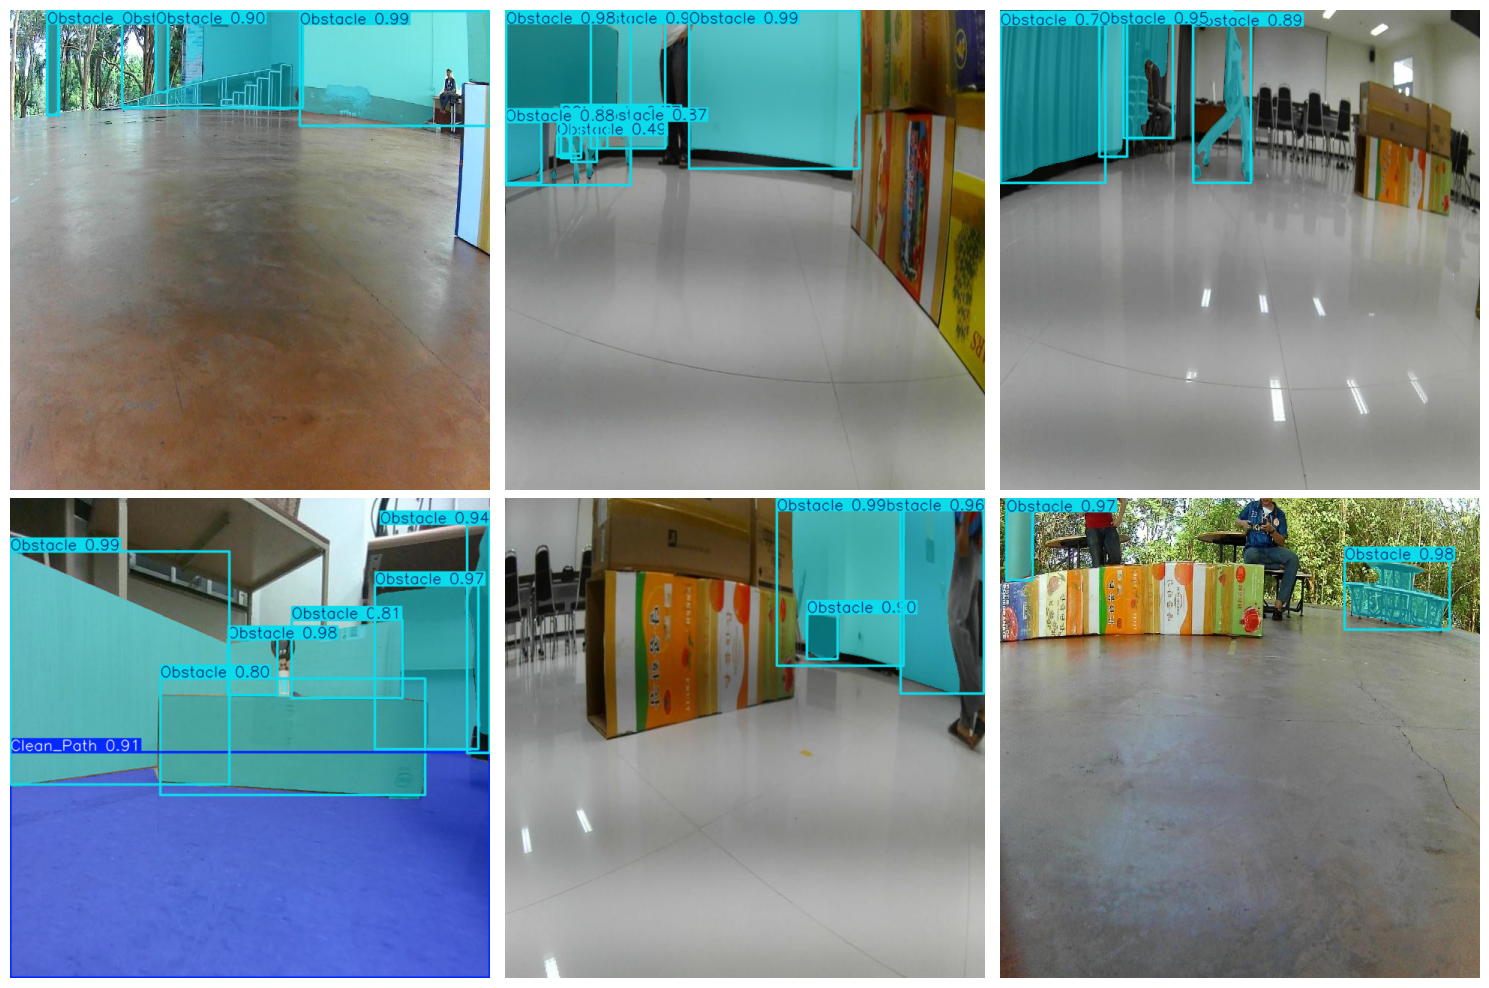

In [ ]:
import matplotlib.pyplot as plt
import random as _r

test_images = list(Path(CONVERTED_DIR, "test", "images").iterdir())
sample = _r.sample(test_images, min(6, len(test_images)))

preds = best_model.predict(source=sample, conf=0.25, save=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, pred in zip(axes.flatten(), preds):
    ax.imshow(pred.plot()[..., ::-1])  # BGR -> RGB
    ax.axis("off")
plt.tight_layout()
plt.show()

### Training curves

In [ ]:
from google.colab import drive
from IPython.display import Image, display
drive.mount('/content/drive')
from pathlib import Path
# display(Image(filename="/content/drive/MyDrive/ISRO/Model_4_3/runs/segment/yolo26n_seg_train/results.png"))

Mounted at /content/drive


In [ ]:
pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.3 MB/s eta 0:00:00


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


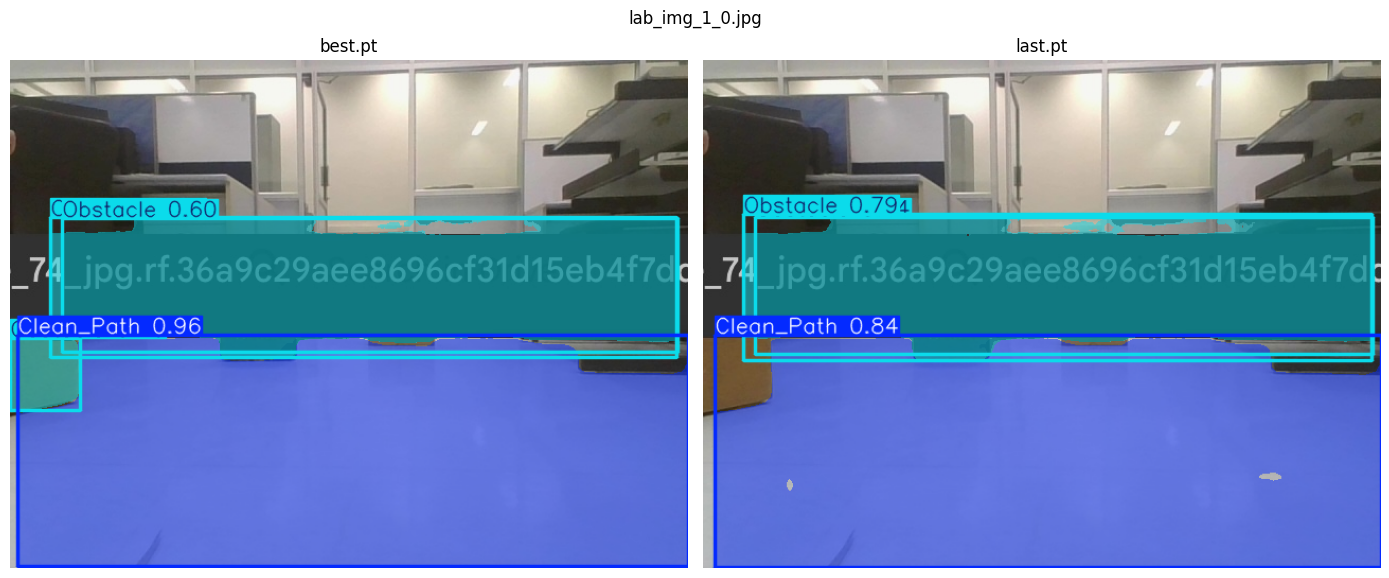

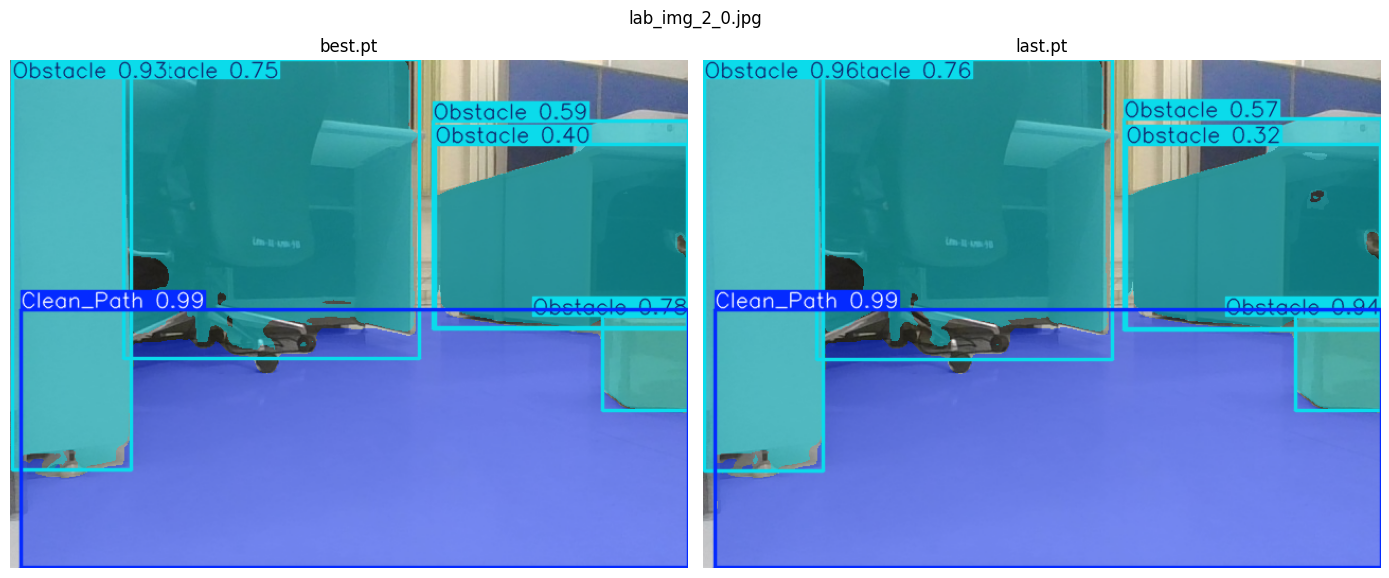

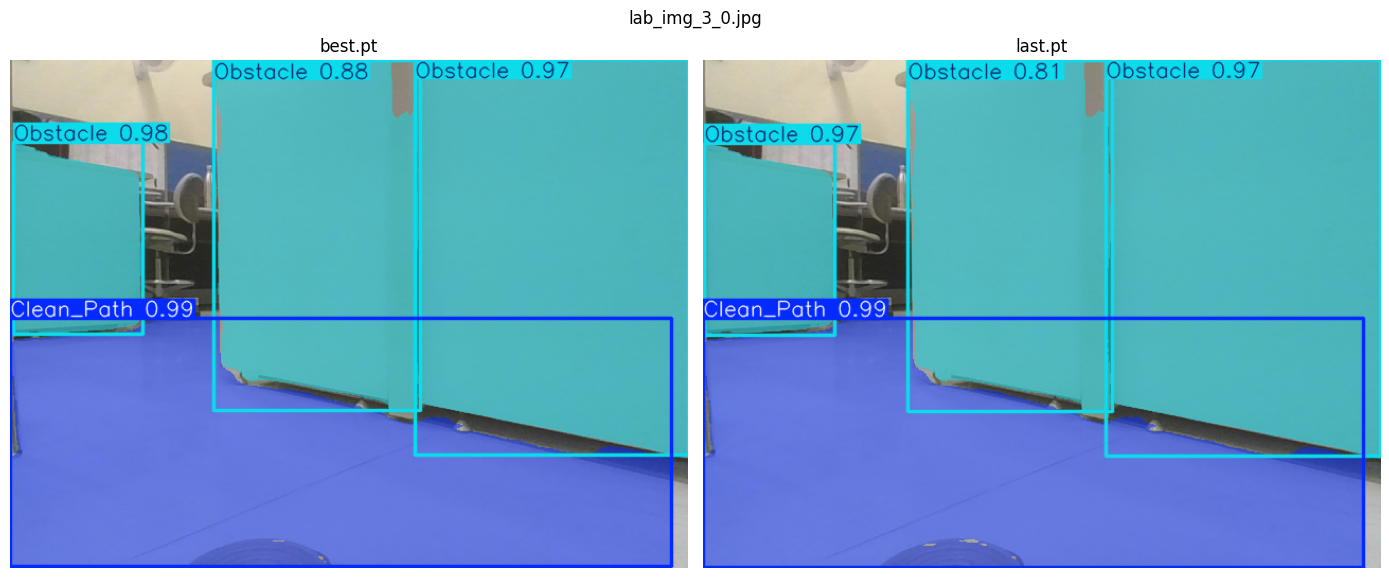

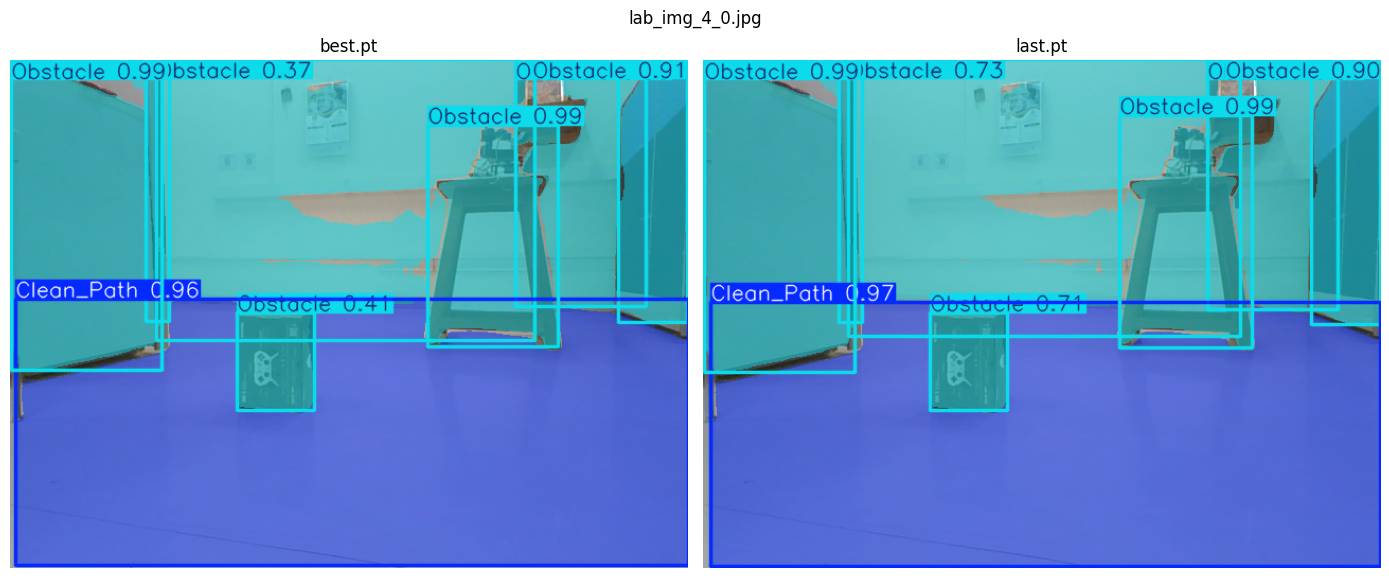

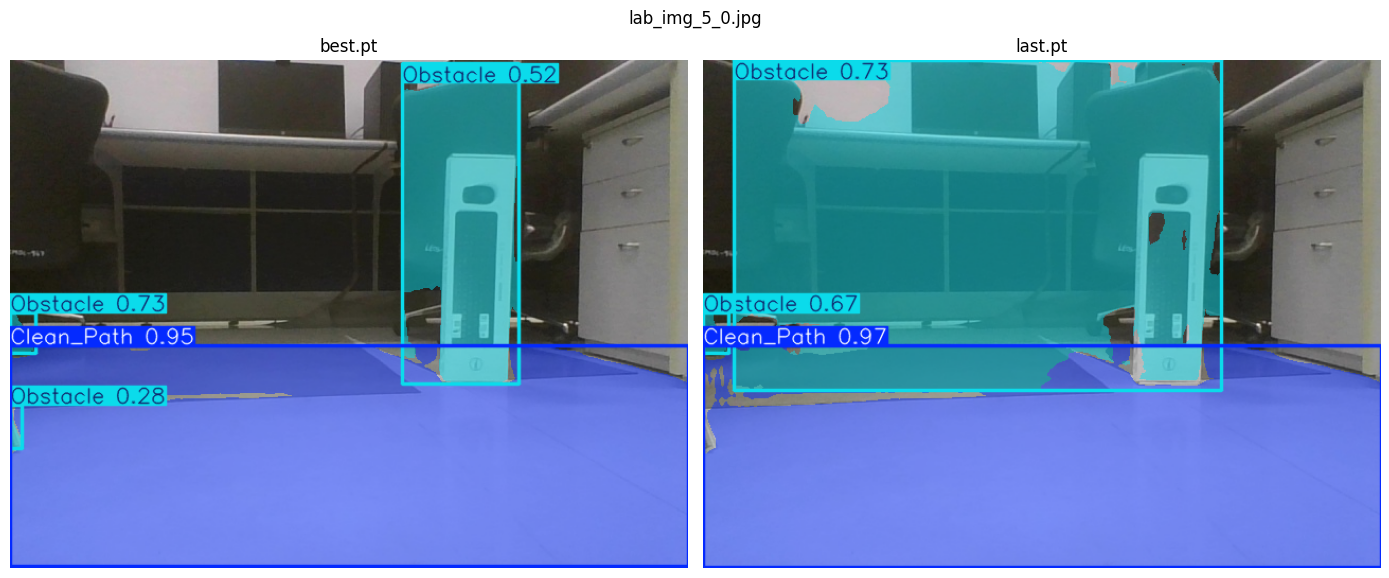

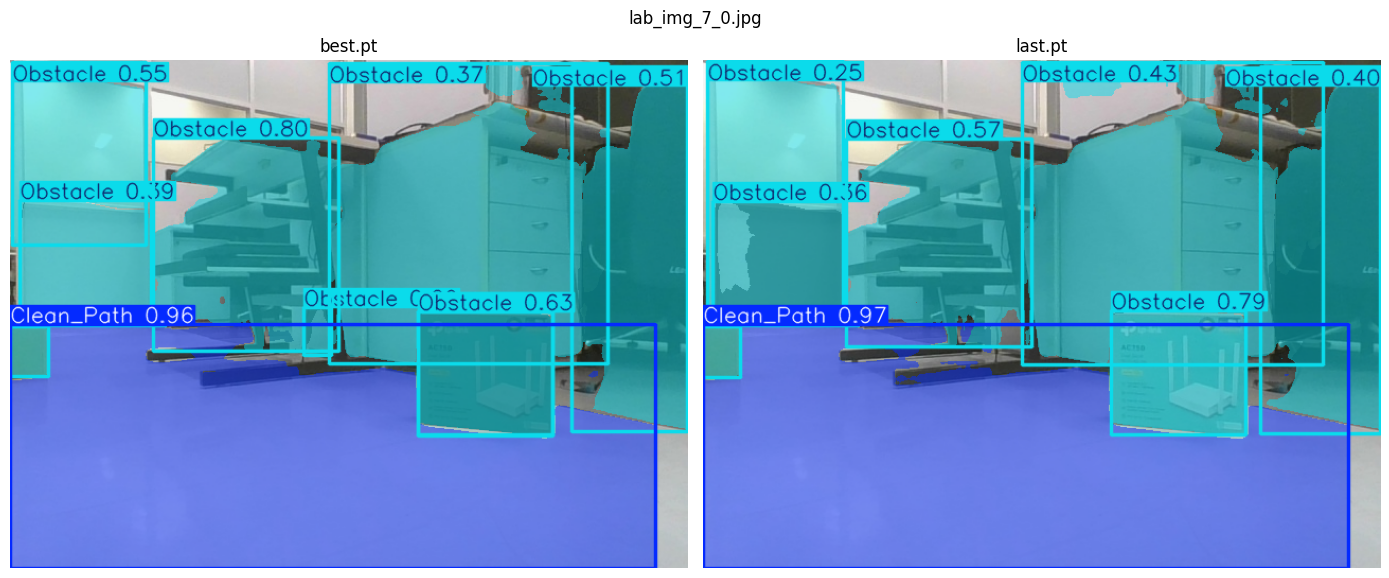

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
from pathlib import Path

# List of images to test
test_images = [
    "/content/lab_img_1_0.jpg",
    "/content/lab_img_2_0.jpg",
    "/content/lab_img_3_0.jpg",
    "/content/lab_img_4_0.jpg",
    "/content/lab_img_5_0.jpg",
    "/content/lab_img_7_0.jpg"
]

weights_dir = "/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/runs/segment/yolo26n_seg_train/weights"

best_model = YOLO(f"{weights_dir}/best.pt")
last_model = YOLO(f"{weights_dir}/last.pt")

for img_path in test_images:

    best_pred = best_model.predict(
        source=img_path,
        conf=0.25,
        save=False,
        verbose=False
    )[0]

    last_pred = last_model.predict(
        source=img_path,
        conf=0.25,
        save=False,
        verbose=False
    )[0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(best_pred.plot()[..., ::-1])   # BGR -> RGB
    axes[0].set_title("best.pt")
    axes[0].axis("off")

    axes[1].imshow(last_pred.plot()[..., ::-1])
    axes[1].set_title("last.pt")
    axes[1].axis("off")

    plt.suptitle(Path(img_path).name)
    plt.tight_layout()
    plt.show()

#Running


Installing Ultralytics package...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Mounting Google Drive...
Mounted at /content/drive

[INFO] Loading weights for Model 1 - Run 1 from: /content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1/weights/best.pt

--- Running Inference with Model 1 - Run 1 ---
Found 5 images to process.
Processing: image_1.png

image 1/1 /content/image_1.png: 480x640 8.5ms
Speed: 114.1ms preprocess, 8.5ms inference, 53.8ms postprocess per image at shape (1, 3, 480, 640)


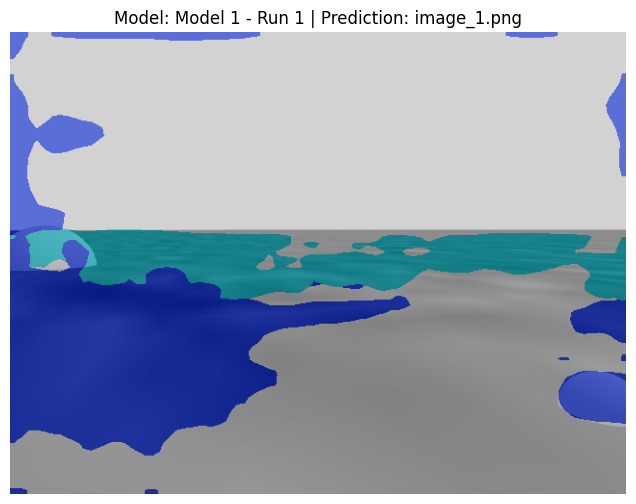

Processing: image_0.png

image 1/1 /content/image_0.png: 480x640 9.8ms
Speed: 2.1ms preprocess, 9.8ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


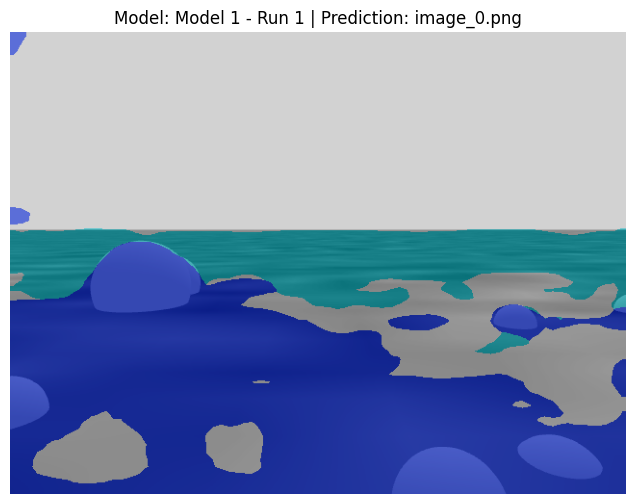

Processing: image_2.png

image 1/1 /content/image_2.png: 480x640 8.3ms
Speed: 1.7ms preprocess, 8.3ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


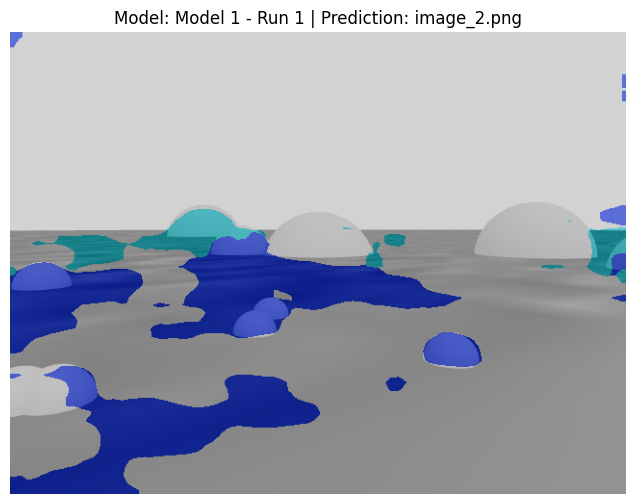

Processing: image_3.png

image 1/1 /content/image_3.png: 480x640 9.0ms
Speed: 1.8ms preprocess, 9.0ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


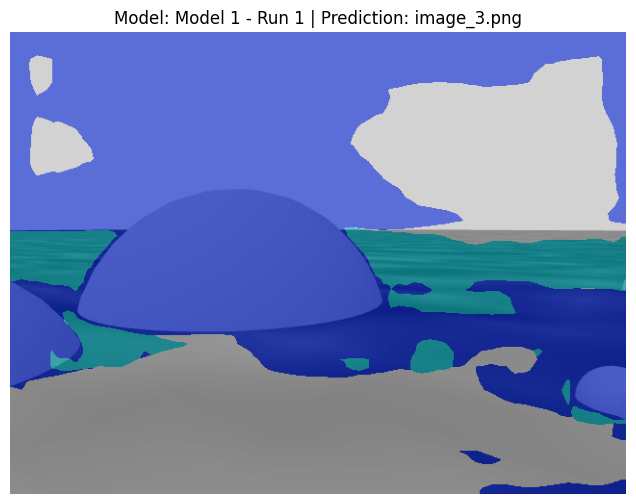

Processing: image_4.png

image 1/1 /content/image_4.png: 480x640 8.3ms
Speed: 1.9ms preprocess, 8.3ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


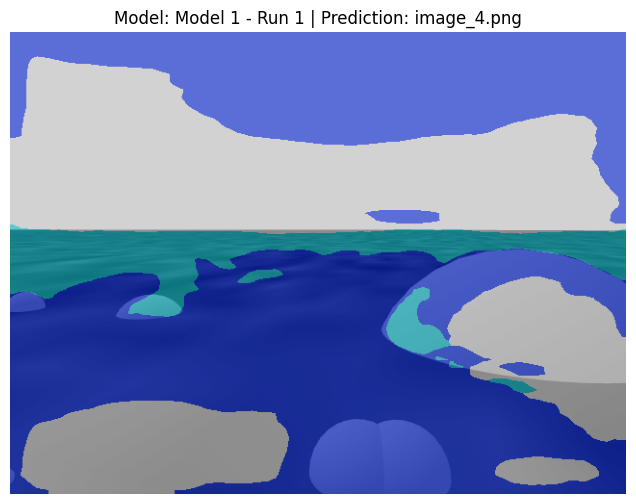


[INFO] Loading weights for Model 1 - Run 1-2 from: /content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1-2/weights/best.pt

--- Running Inference with Model 1 - Run 1-2 ---
Found 5 images to process.
Processing: image_1.png

image 1/1 /content/image_1.png: 480x640 5.2ms
Speed: 1.7ms preprocess, 5.2ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


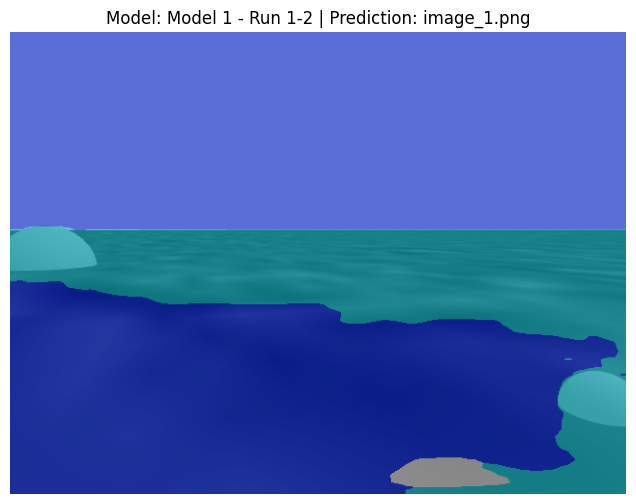

Processing: image_0.png

image 1/1 /content/image_0.png: 480x640 9.0ms
Speed: 2.0ms preprocess, 9.0ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


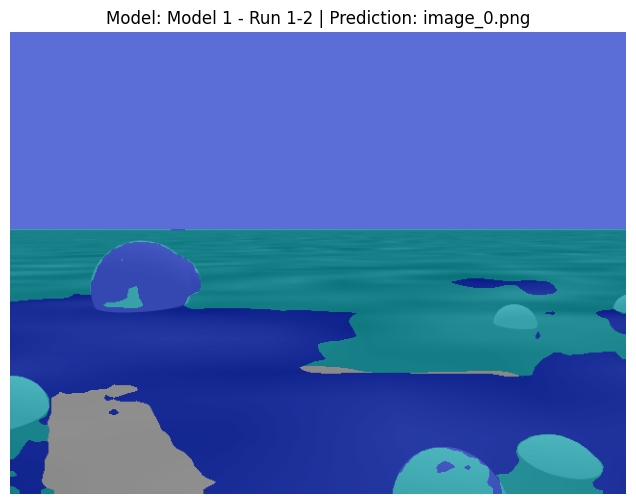

Processing: image_2.png

image 1/1 /content/image_2.png: 480x640 9.1ms
Speed: 1.9ms preprocess, 9.1ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


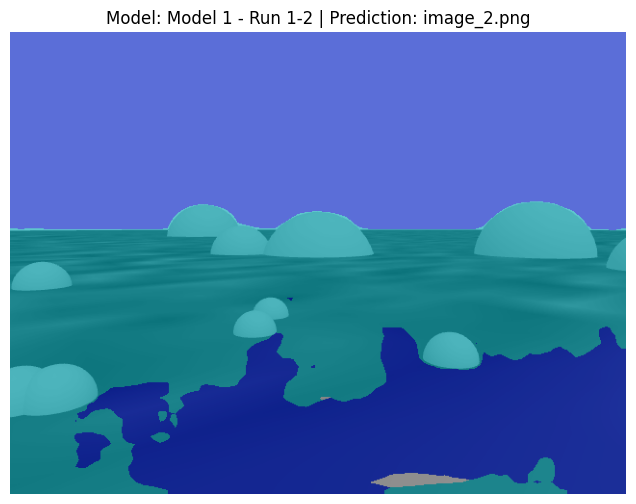

Processing: image_3.png

image 1/1 /content/image_3.png: 480x640 9.4ms
Speed: 1.7ms preprocess, 9.4ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


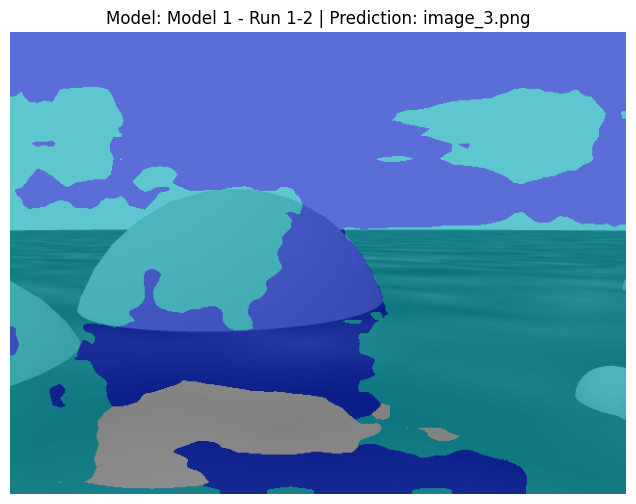

Processing: image_4.png

image 1/1 /content/image_4.png: 480x640 10.6ms
Speed: 2.0ms preprocess, 10.6ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


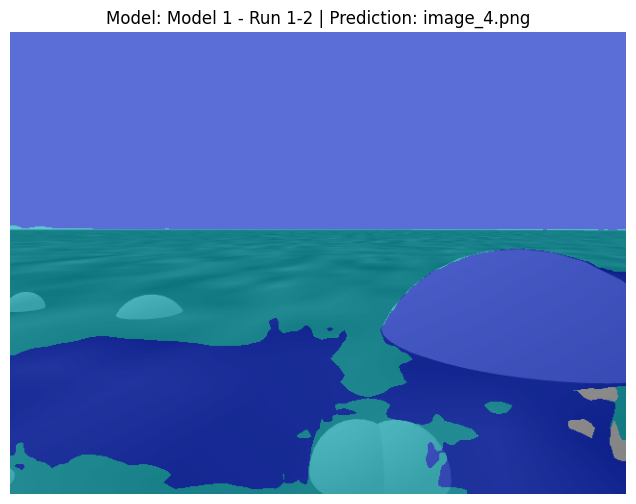


[INFO] Loading weights for Model 2 - Run 1 from: /content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_1/weights/best.pt

--- Running Inference with Model 2 - Run 1 ---
Found 5 images to process.
Processing: image_1.png

image 1/1 /content/image_1.png: 480x640 11.3ms
Speed: 2.4ms preprocess, 11.3ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


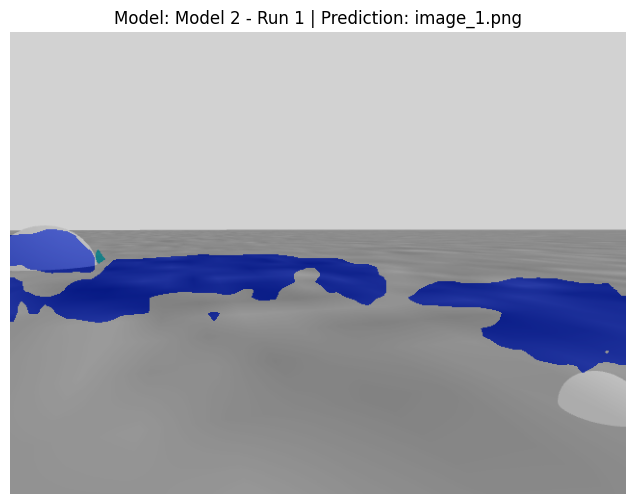

Processing: image_0.png

image 1/1 /content/image_0.png: 480x640 13.9ms
Speed: 1.8ms preprocess, 13.9ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


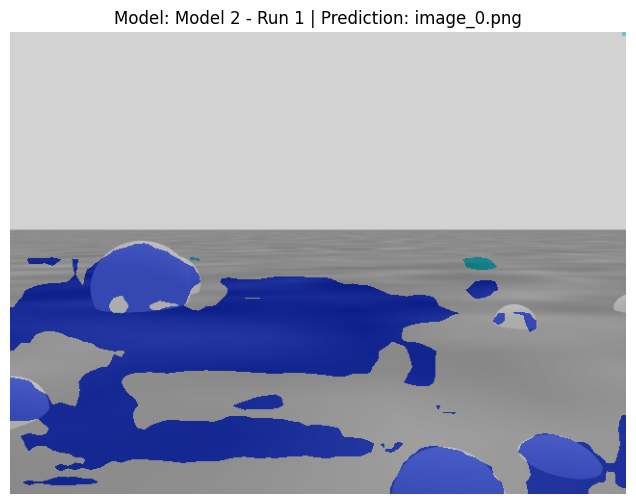

Processing: image_2.png

image 1/1 /content/image_2.png: 480x640 13.3ms
Speed: 1.7ms preprocess, 13.3ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


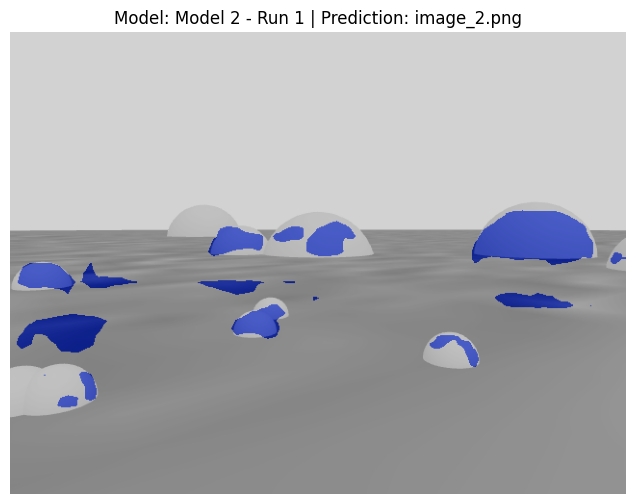

Processing: image_3.png

image 1/1 /content/image_3.png: 480x640 10.6ms
Speed: 1.8ms preprocess, 10.6ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


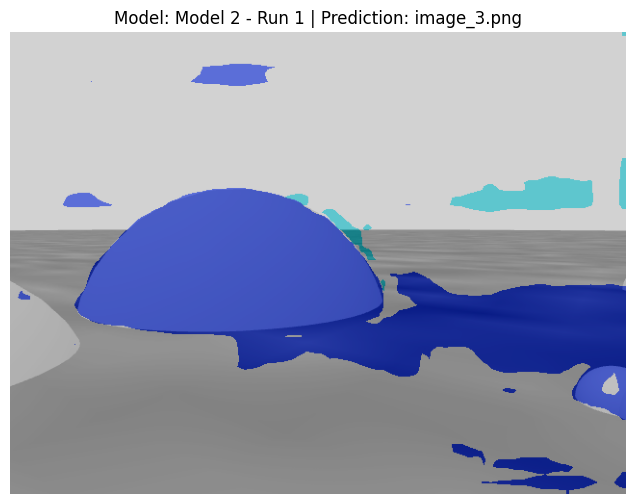

Processing: image_4.png

image 1/1 /content/image_4.png: 480x640 14.1ms
Speed: 4.0ms preprocess, 14.1ms inference, 2.5ms postprocess per image at shape (1, 3, 480, 640)


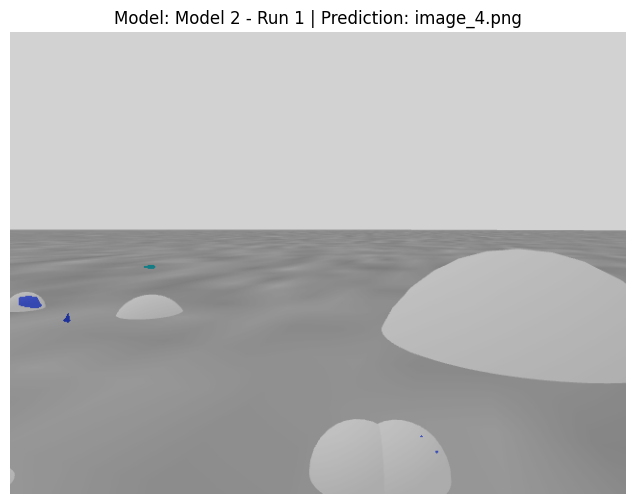


[INFO] Loading weights for Model 2 - Run 2 from: /content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_2/weights/best.pt

--- Running Inference with Model 2 - Run 2 ---
Found 5 images to process.
Processing: image_1.png

image 1/1 /content/image_1.png: 480x640 6.2ms
Speed: 1.9ms preprocess, 6.2ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


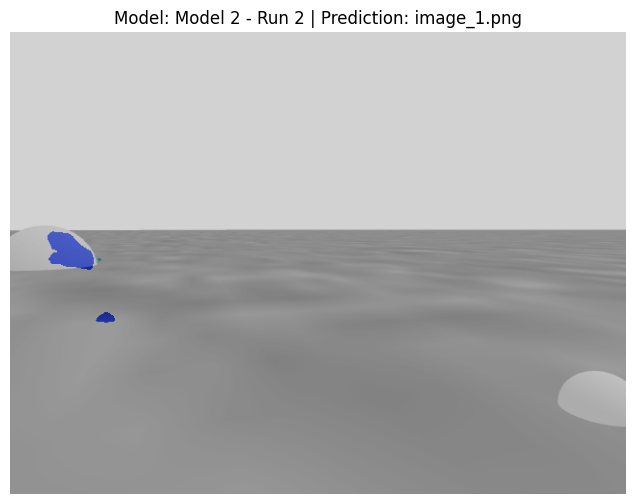

Processing: image_0.png

image 1/1 /content/image_0.png: 480x640 9.7ms
Speed: 2.0ms preprocess, 9.7ms inference, 0.2ms postprocess per image at shape (1, 3, 480, 640)


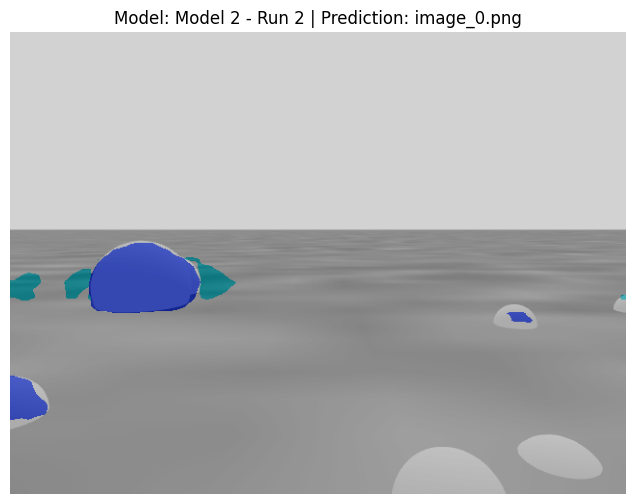

Processing: image_2.png

image 1/1 /content/image_2.png: 480x640 10.0ms
Speed: 2.0ms preprocess, 10.0ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


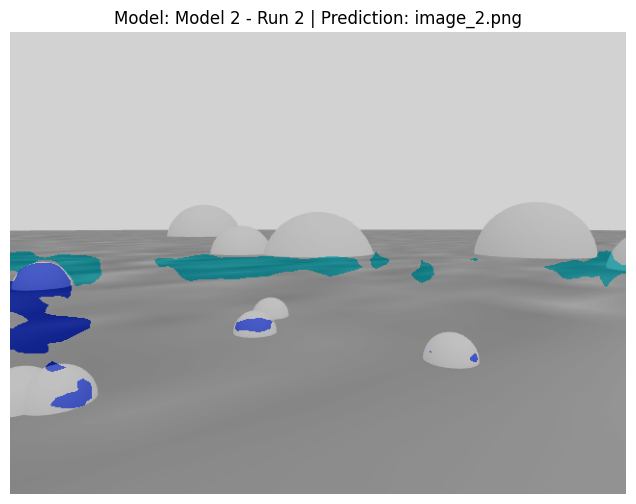

Processing: image_3.png

image 1/1 /content/image_3.png: 480x640 10.6ms
Speed: 1.9ms preprocess, 10.6ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


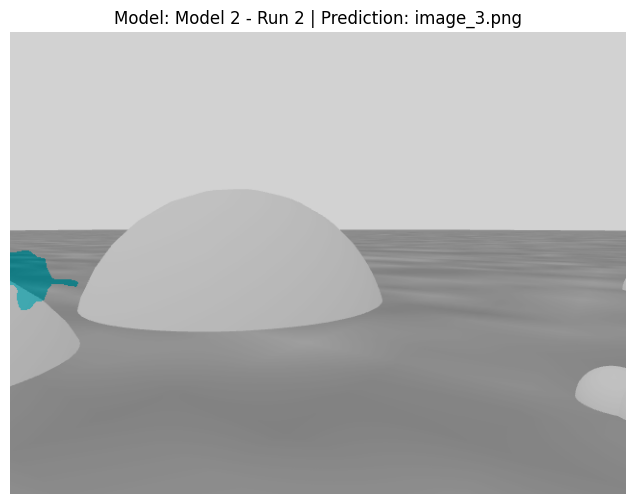

Processing: image_4.png

image 1/1 /content/image_4.png: 480x640 8.7ms
Speed: 1.9ms preprocess, 8.7ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


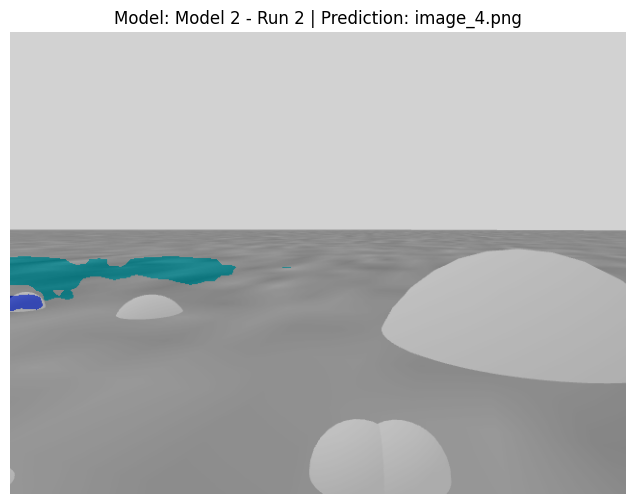


[INFO] Loading weights for Model 3 - Segment Train from: /content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/runs/segment/yolo26n_seg_train/weights/best.pt

--- Running Inference with Model 3 - Segment Train ---
Found 5 images to process.
Processing: image_1.png

image 1/1 /content/image_1.png: 480x640 (no detections), 13.5ms
Speed: 2.0ms preprocess, 13.5ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


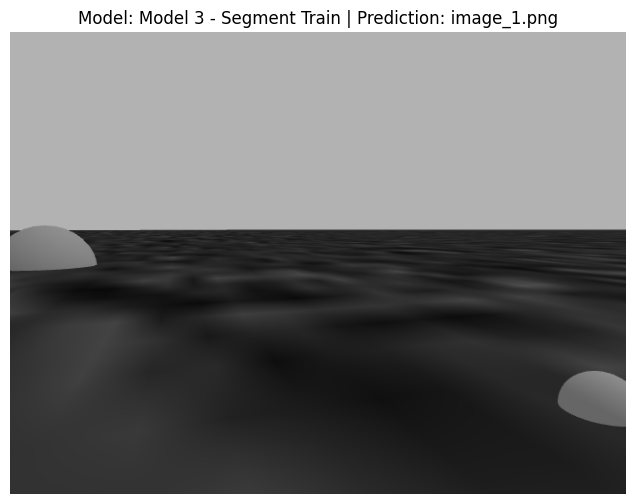

Processing: image_0.png

image 1/1 /content/image_0.png: 480x640 (no detections), 19.4ms
Speed: 2.1ms preprocess, 19.4ms inference, 0.4ms postprocess per image at shape (1, 3, 480, 640)


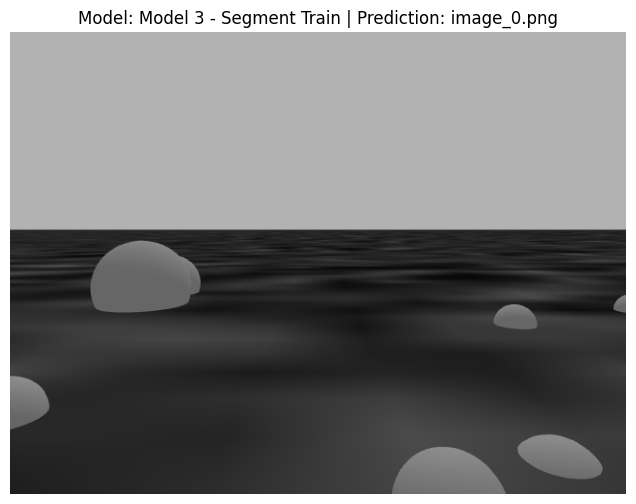

Processing: image_2.png

image 1/1 /content/image_2.png: 480x640 1 Obstacle, 17.9ms
Speed: 1.9ms preprocess, 17.9ms inference, 102.9ms postprocess per image at shape (1, 3, 480, 640)


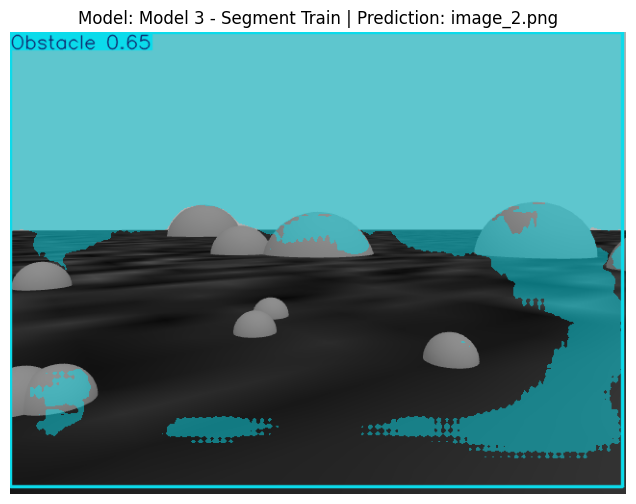

Processing: image_3.png

image 1/1 /content/image_3.png: 480x640 (no detections), 20.4ms
Speed: 2.1ms preprocess, 20.4ms inference, 0.3ms postprocess per image at shape (1, 3, 480, 640)


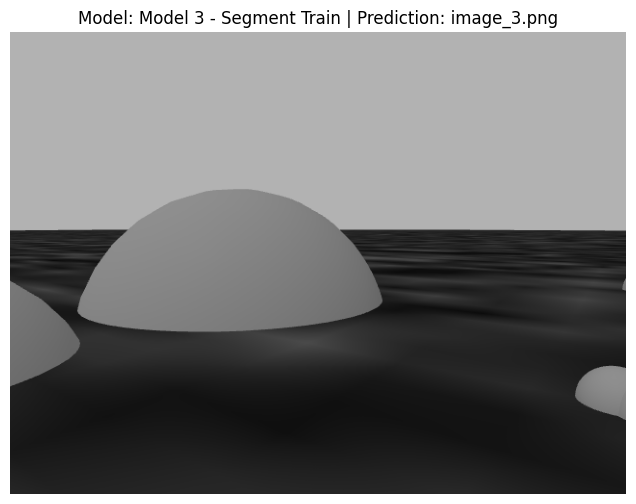

Processing: image_4.png

image 1/1 /content/image_4.png: 480x640 1 Obstacle, 20.3ms
Speed: 2.4ms preprocess, 20.3ms inference, 1.5ms postprocess per image at shape (1, 3, 480, 640)


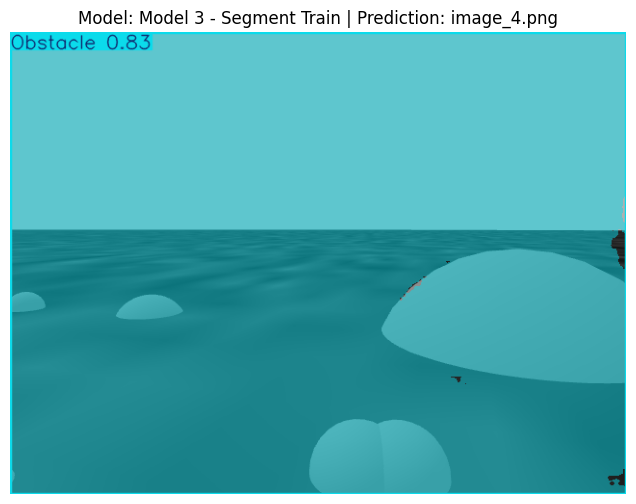


[WARNING] Weights file for 'Model 3 - Instance Best' not found at: /content/drive/MyDrive/ISRO/Model_4_3/Instance_model/best_yolo26n_seg.pt


In [ ]:
import os
from google.colab import drive
import matplotlib.pyplot as plt
import cv2

# Step 1: Install Ultralytics library (if not already installed)
try:
    import ultralytics
    print("Ultralytics library is ready.")
except ImportError:
    print("Installing Ultralytics package...")
    !pip install ultralytics -q
    import ultralytics

from ultralytics import YOLO

# Step 2: Mount Google Drive to access your saved weights
if not os.path.exists('/content/drive'):
    print("Mounting Google Drive...")
    drive.mount('/content/drive')
else:
    print("Google Drive is already mounted.")

# ==========================================
# CONFIGURATION: Dictionary of Model Paths
# ==========================================
MODEL_PATHS = {
    "Model 1 - Run 1": '/content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1/weights/best.pt',
    "Model 1 - Run 1-2": '/content/drive/MyDrive/IGVC_dataset_ISRO/runs/run1-2/weights/best.pt',
    "Model 2 - Run 1": '/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_1/weights/best.pt',
    "Model 2 - Run 2": '/content/drive/MyDrive/IGVC_dataset_ISRO/additional_dataset/raw/Model_2/runs/run_2/weights/best.pt',
    "Model 3 - Segment Train": '/content/drive/MyDrive/ISRO/Model_4_3/Instance_dataset_converted/runs/segment/yolo26n_seg_train/weights/best.pt',
    "Model 3 - Instance Best": '/content/drive/MyDrive/ISRO/Model_4_3/Instance_model/best_yolo26n_seg.pt'
}

TEST_IMAGE_DIR = '/content/'  # Path containing your test images
# ==========================================

# Step 3: Run inference function
def run_inference_on_folder(model, model_name, image_folder, confidence_threshold=0.25):
    # Retrieve all valid image files in the directory
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    images = [f for f in os.listdir(image_folder) if f.lower().endswith(valid_extensions)]

    if not images:
        print(f"No images found in directory: {image_folder}")
        print("Please upload your test images to the /content/ folder.")
        return

    print(f"\n--- Running Inference with {model_name} ---")
    print(f"Found {len(images)} images to process.")

    for img_name in images:
        img_path = os.path.join(image_folder, img_name)
        print(f"Processing: {img_name}")

        # Run inference using the loaded model weights
        try:
            results = model.predict(source=img_path, conf=confidence_threshold, device='0') # Uses GPU (device='0')
        except Exception as e:
            print(f"GPU execution failed or unavailable, falling back to CPU. Error: {e}")
            results = model.predict(source=img_path, conf=confidence_threshold, device='cpu')

        # Plot and display the segmented prediction results
        for r in results:
            im_array = r.plot()  # Plots BGR numpy array with masks/boxes annotated
            im_rgb = cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(10, 6))
            plt.imshow(im_rgb)
            plt.title(f"Model: {model_name} | Prediction: {img_name}")
            plt.axis('off')
            plt.show()

# Step 4: Execute inference loop across all defined models
for model_name, path in MODEL_PATHS.items():
    if os.path.exists(path):
        print(f"\n[INFO] Loading weights for {model_name} from: {path}")
        try:
            model = YOLO(path)
            run_inference_on_folder(model, model_name, TEST_IMAGE_DIR, confidence_threshold=0.30)
        except Exception as e:
            print(f"[ERROR] Failed to load/run {model_name}. Error: {e}")
    else:
        print(f"\n[WARNING] Weights file for '{model_name}' not found at: {path}")